import and data


In [1]:
import json, time, os, random
import pandas as pd, numpy as np
import ollama
from tqdm import tqdm
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

random.seed(42)
os.makedirs("../results", exist_ok=True)

dev   = pd.read_csv("../data/po_dev.csv")
train = pd.read_csv("../data/po_train.csv")
print(len(dev), "dev POs:", dev.label.value_counts().to_dict())

498 dev POs: {'normal': 460, 'violation': 38}


prepare and features

In [2]:
tx = pd.read_csv("../data/transactions.csv", parse_dates=["timestamp"])
vendors = pd.read_csv("../data/vendors.csv")
VENDOR_CREATOR = vendors.set_index("vendor_id")["created_by"].to_dict()

piv  = tx.pivot(index="po_number", columns="event_type", values="user_id")
meta = tx[tx.event_type == "PO_CREATED"].set_index("po_number")[["vendor_id", "amount", "timestamp"]]
base = piv.join(meta)
base["vendor_creator"] = base["vendor_id"].map(VENDOR_CREATOR)

# how many OTHER POs did the same creator raise to the same vendor within 7 days?
cr = base.reset_index()[["po_number", "PO_CREATED", "vendor_id", "timestamp"]].rename(
        columns={"PO_CREATED": "creator"})
cnt = {}
for (c, v), g in cr.groupby(["creator", "vendor_id"]):
    for po, t in zip(g.po_number, g.timestamp):
        cnt[po] = int(((g.timestamp - t).abs() <= pd.Timedelta(days=7)).sum()) - 1
base["same_vendor_7d"] = pd.Series(cnt)

rules

In [3]:
def rule_predict(r):
    if r.PO_CREATED == r.PAYMENT_POSTED:                      return "SOD_CREATE_PAY"
    if pd.isna(r.PO_APPROVED):                                return "MISSING_APPROVAL"
    if r.PO_CREATED == r.PO_APPROVED:                         return "SELF_APPROVAL"
    if r.PAYMENT_POSTED == r.vendor_creator:                  return "VENDOR_CREATE_PAY"
    if 45000 <= r.amount < 50000 and r.same_vendor_7d >= 3:   return "SPLIT_BELOW_THRESHOLD"
    return "NONE"

base["rule_pred"] = base.apply(rule_predict, axis=1)

metrics helpers and baseline score

In [4]:
def binary_metrics(y_true, y_pred):
    return dict(precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0))

d = dev.merge(base[["rule_pred"]], left_on="po_number", right_index=True)
y_true = (d.label == "violation").astype(int)
y_pred = (d.rule_pred != "NONE").astype(int)

rule_row = binary_metrics(y_true, y_pred)
rule_row.update(type_acc_on_violations=(d[d.label=="violation"].violation_type ==
                                        d[d.label=="violation"].rule_pred).mean(),
                invalid_json=0.0, sec_per_case=0.0, n=len(d), name="rules_baseline")
print(rule_row)
print(confusion_matrix(y_true, y_pred))   # [[TN FP],[FN TP]]

{'precision': 0.926829268292683, 'recall': 1.0, 'f1': 0.9620253164556962, 'type_acc_on_violations': np.float64(1.0), 'invalid_json': 0.0, 'sec_per_case': 0.0, 'n': 498, 'name': 'rules_baseline'}
[[457   3]
 [  0  38]]


output schema and policy prompt

In [5]:
TYPES = ["NONE", "SOD_CREATE_PAY", "SELF_APPROVAL", "VENDOR_CREATE_PAY",
         "MISSING_APPROVAL", "SPLIT_BELOW_THRESHOLD"]

SCHEMA = {"type": "object",
          "properties": {
              "reason":         {"type": "string"},
              "violation":      {"type": "boolean"},
              "violation_type": {"type": "string", "enum": TYPES}},
          "required": ["reason", "violation", "violation_type"]}

POLICY = """You are an ERP access-control auditor. You review one purchase order (PO) at a time.
A PO normally goes: created -> approved -> goods received -> invoice posted -> payment posted, handled by different people.
Policy rules:
1. SOD_CREATE_PAY: the user who created the PO must not also post its payment.
2. SELF_APPROVAL: the user who created the PO must not approve it.
3. VENDOR_CREATE_PAY: the user who created the vendor must not post payments to that vendor.
4. MISSING_APPROVAL: every PO must have an approval step before payment.
5. SPLIT_BELOW_THRESHOLD: flag only if the context shows 3 or more other POs by the same creator to the same vendor within 7 days AND the amount is within 10% below the INR 50,000 limit.
Having conflicting roles is NOT a violation by itself. It is a violation only if the conflicting access was actually used on this PO.
Compare the user ids in each step carefully.
Reply in JSON with: reason (one short sentence), violation (true or false), violation_type (one of the codes, or NONE)."""

call function

In [6]:
def ask(model, messages):
    t0 = time.time()
    r = ollama.chat(model=model, messages=messages, format=SCHEMA,
                    options={"temperature": 0, "seed": 42, "num_predict": 200, "num_ctx": 4096},
                    keep_alive="30m")
    wall = time.time() - t0
    txt = r["message"]["content"]
    try:
        o = json.loads(txt)
        return dict(pred_violation=bool(o["violation"]), pred_type=o["violation_type"],
                    reason=o["reason"], valid_json=True, sec=wall,
                    out_tokens=getattr(r, "eval_count", None))
    except Exception:
        return dict(pred_violation=False, pred_type="INVALID", reason=txt[:200],
                    valid_json=False, sec=wall, out_tokens=getattr(r, "eval_count", None))

def unload(model):
    ollama.generate(model=model, prompt="", keep_alive=0)

zero shot and few shot prompt builder

In [7]:
def zero_shot(summary):
    return [{"role": "system", "content": POLICY},
            {"role": "user", "content": summary}]

REASON = {
 "NONE": "Different users handled creation, approval and payment, and no rule is broken.",
 "SOD_CREATE_PAY": "The same user created the PO and posted its payment.",
 "SELF_APPROVAL": "The creator of the PO also approved it.",
 "VENDOR_CREATE_PAY": "The user who created the vendor also posted the payment.",
 "MISSING_APPROVAL": "There is no approval step before payment.",
 "SPLIT_BELOW_THRESHOLD": "Several POs to the same vendor by the same creator within a week, each just under the limit.",
}

# one example per type, plus a hard negative (a normal PO touched by a conflict-role user)
FEWSHOT = [train[train.violation_type == t].sample(1, random_state=7).iloc[0] for t in TYPES]
FEWSHOT.append(train[(train.violation_type == "NONE") &
                     train.summary.str.contains(r"\|")].sample(1, random_state=8).iloc[0])
random.Random(3).shuffle(FEWSHOT)

def few_shot(summary):
    msgs = [{"role": "system", "content": POLICY}]
    for r in FEWSHOT:
        msgs.append({"role": "user", "content": r.summary})
        msgs.append({"role": "assistant", "content": json.dumps({
            "reason": REASON[r.violation_type],
            "violation": r.violation_type != "NONE",
            "violation_type": r.violation_type})})
    msgs.append({"role": "user", "content": summary})
    return msgs

experiment runner and evaluator

In [8]:
def run_eval(model, mode, df, tag):
    path = f"../results/phase3_{tag}.csv"
    rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
    done = {r["po_number"] for r in rows}
    build = zero_shot if mode == "zero" else few_shot
    for r in tqdm(df.itertuples(), total=len(df)):
        if r.po_number in done:
            continue
        out = ask(model, build(r.summary))
        rows.append(dict(po_number=r.po_number, true_label=r.label, true_type=r.violation_type, **out))
        if len(rows) % 25 == 0:
            pd.DataFrame(rows).to_csv(path, index=False)
    res = pd.DataFrame(rows); res.to_csv(path, index=False)
    return res

def evaluate(res, name):
    y_t = (res.true_label == "violation").astype(int)
    y_p = res.pred_violation.astype(int)
    m = binary_metrics(y_t, y_p)
    v = res[res.true_label == "violation"]
    m.update(type_acc_on_violations=(v.pred_type == v.true_type).mean(),
             invalid_json=1 - res.valid_json.mean(), sec_per_case=res.sec.mean(),
             n=len(res), name=name)
    return m

smoke test on 5 cases

In [9]:
sample = dev.sample(5, random_state=0)
for r in sample.itertuples():
    out = ask("llama3.2:3b", zero_shot(r.summary))
    print(r.po_number, "TRUE:", r.violation_type, "| PRED:", out["pred_type"],
          "|", round(out["sec"], 1), "s |", out["reason"])

PO-10948 TRUE: NONE | PRED: MISSING_APPROVAL | 4.1 s | PO has been posted without approval
PO-12517 TRUE: NONE | PRED: SOD_CREATE_PAY | 0.6 s | Payment posted by U035 without approval from U016
PO-12793 TRUE: NONE | PRED: NONE | 0.5 s | PO meets all policy rules
PO-14448 TRUE: NONE | PRED: SOD_CREATE_PAY | 0.5 s | Payment posted by PO creator
PO-13235 TRUE: NONE | PRED: NONE | 0.5 s | PO meets all policy rules


build quick set

In [10]:
quick = pd.concat([
    dev[dev.label == "violation"].groupby("violation_type").head(8),
    dev[dev.label == "normal"].sample(40, random_state=1)
]).sample(frac=1, random_state=1).reset_index(drop=True)
print(len(quick), quick.label.value_counts().to_dict())

75 {'normal': 40, 'violation': 35}


run all four configs

In [11]:
results = []
for m in ["llama3.2:3b", "qwen2.5:3b"]:
    for mode in ["zero", "few"]:
        tag = f"quick_{m.replace(':','_')}_{mode}"
        res = run_eval(m, mode, quick, tag)
        results.append(evaluate(res, tag))
    unload(m)
pd.DataFrame(results).round(3)

100%|██████████| 75/75 [00:42<00:00,  1.78it/s]


,precision,recall,f1,type_acc_on_violations,invalid_json,sec_per_case,n,name
0,0.650,0.743,0.693,0.371,0.0,0.513,75,quick_llama3.2_3b_zero
1,0.698,0.857,0.769,0.343,0.0,0.545,75,quick_llama3.2_3b_few
2,0.467,1.000,0.636,0.229,0.0,0.825,75,quick_qwen2.5_3b_zero
3,0.484,0.857,0.619,0.514,0.0,0.559,75,quick_qwen2.5_3b_few


run best config on all devs

# quick_llama3.2_3b_few Wins Overall
## highest f1 score
## highest precision
## strong recall
## not quick_qwen2.5:3b_zero as its 1.000 recall comes with 0.467 precision

In [13]:
BEST = [("llama3.2:3b", "few")]      
full_results = []
for m, mode in BEST:
    tag = f"full_{m.replace(':','_')}_{mode}"
    res = run_eval(m, mode, dev, tag)
    full_results.append(evaluate(res, tag))
    unload(m)
pd.DataFrame(full_results).round(3)

100%|██████████| 498/498 [04:44<00:00,  1.75it/s]


,precision,recall,f1,type_acc_on_violations,invalid_json,sec_per_case,n,name
0,0.138,0.842,0.237,0.342,0.0,0.57,498,full_llama3.2_3b_few


In [14]:
full_results = []
for m in ["llama3.2:3b", "qwen2.5:3b"]:
    for mode in ["zero", "few"]:
        tag = f"full_{m.replace(':','_')}_{mode}"
        res = run_eval(m, mode, dev, tag)      # the finished one is skipped
        full_results.append(evaluate(res, tag))
    unload(m)
pd.DataFrame(full_results).round(3)

100%|██████████| 498/498 [04:54<00:00,  1.69it/s]


,precision,recall,f1,type_acc_on_violations,invalid_json,sec_per_case,n,name
0,0.100,0.737,0.177,0.342,0.0,0.583,498,full_llama3.2_3b_zero
1,0.138,0.842,0.237,0.342,0.0,0.570,498,full_llama3.2_3b_few
2,0.076,1.000,0.142,0.237,0.0,0.922,498,full_qwen2.5_3b_zero
3,0.079,0.895,0.145,0.553,0.0,0.591,498,full_qwen2.5_3b_few


where model fails

In [16]:
res = pd.read_csv("../results/phase3_full_llama3.2_3b_few.csv")
look = res.merge(dev[["po_number", "summary"]], on="po_number")

fp = look[(look.true_label == "normal") & (look.pred_violation)]
fn = look[(look.true_label == "violation") & (~look.pred_violation)]
print(len(fp), "false positives |", len(fn), "false negatives")

v = look[look.true_label == "violation"].copy()
v["detected"] = v.pred_violation.astype(int)
v["type_ok"]  = (v.pred_type == v.true_type).astype(int)
print(v.groupby("true_type")[["detected", "type_ok"]].mean().join(v.groupby("true_type").size().rename("n")))

200 false positives | 6 false negatives
                       detected   type_ok  n
true_type                                   
MISSING_APPROVAL       0.444444  0.000000  9
SELF_APPROVAL          1.000000  0.666667  9
SOD_CREATE_PAY         1.000000  0.000000  9
SPLIT_BELOW_THRESHOLD  0.750000  0.000000  4
VENDOR_CREATE_PAY      1.000000  1.000000  7


actual mistakes

In [17]:
def show(df, n=5):
    for _, r in df.head(n).iterrows():
        print(r.summary); print(">> MODEL:", r.pred_type, "-", r.reason)
        print(">> TRUTH:", r.true_type); print("=" * 70)

show(fp)   # false alarms
show(fn)   # missed violations

PO PO-10067 | vendor V023 | amount INR 55,890
1. Created by U006 (roles: PO_CREATOR) on 2026-02-09 15:36
2. Approved by U015 (roles: PO_APPROVER) on 2026-02-10 19:36
3. Goods received by U021 (roles: WAREHOUSE) on 2026-02-18 19:36
4. Invoice posted by U028 (roles: AP_CLERK) on 2026-02-23 19:36
5. Payment posted by U048 (roles: VENDOR_ADMIN|PAYMENT_PROCESSOR) on 2026-03-01 19:36
Context: vendor V023 was created by U050. Other POs by the same creator to this vendor within 7 days: 0. Amount within 10% below the INR 50,000 limit: no.
>> MODEL: VENDOR_CREATE_PAY - The user who created the vendor also posted the payment.
>> TRUTH: NONE
PO PO-10076 | vendor V032 | amount INR 109,990
1. Created by U047 (roles: PO_CREATOR|PAYMENT_PROCESSOR) on 2026-03-02 11:24
2. Approved by U018 (roles: PO_APPROVER) on 2026-03-03 08:24
3. Goods received by U025 (roles: WAREHOUSE) on 2026-03-06 08:24
4. Invoice posted by U029 (roles: AP_CLERK) on 2026-03-10 08:24
5. Payment posted by U045 (roles: PO_CREATOR|PAY

## Error Analysis & Why Prompting Isn't Enough

I looked through 10 of the model's errors from the full run (5 false positives and 5 false negatives) and grouped them into patterns. Combined with the full 498-case benchmark ($32$ TPs, $200$ FPs, $6$ FNs), here is what is actually going wrong:

- **Comparing the wrong IDs (5/5 sample false positives):** The model constantly hallucinates that different users are the same person. For example, in `PO-10067`, vendor `V023` was created by `U050`, but payment was posted by `U048`. The model just says they match and flags a violation. Across the whole dataset, this is the main reason we get around 200 false positives.
- **Flagged roles alone (5/5 false positives):** Whenever a user holds a dual role (like `VENDOR_ADMIN|PAYMENT_PROCESSOR` or `PO_CREATOR|PAYMENT_PROCESSOR`), the model immediately assumes guilt. In `PO-10067`, `PO-10085`, and `PO-10137`, it flagged the payment user purely based on their role string without checking whether they actually created that specific vendor or PO.
- **Missing workflow steps (5/5 false negatives):** The model is completely blind to absent data. In `PO-14878` through `PO-14915`, the approval step (`2. Approved by...`) is totally missing from the 4-step log. Instead of catching the missing approval, the model hallucinates that different users handled creation, approval, and payment smoothly, returning `NONE` every time.
- **Wrong violation code on true positives (19/32 true positives):** Even when the model successfully catches a violation (`recall = 0.842`), it mislabels most of them (`type_acc = 0.342`). It defaults almost everything to `VENDOR_CREATE_PAY` even when the underlying issue is different.
- **JSON & Reasoning:** On the bright side, Ollama's `format="json"` worked perfectly (0.0% invalid JSON), and few-shot prompting kept the boolean verdicts aligned with the text explanations without contradicting themselves.

### Conclusion for Fine-Tuning
Prompting a 3B model isn't enough for an ERP audit pipeline. It gets tripped up by role strings, fails at basic string equality between User IDs, and completely misses skipped steps because it expects a standard 5-step template. To fix this, we need either fine-tuning on domain-specific ERP data or a hybrid rule-based layer that handles exact ID matching and step-counting deterministically, leaving the LLM just for the final explanation.

summary

,precision,recall,f1,type_acc_on_violations,invalid_json,sec_per_case,n
name,,,,,,,
rules_baseline,0.927,1.000,0.962,1.000,0.0,0.000,498
full_llama3.2_3b_zero,0.100,0.737,0.177,0.342,0.0,0.583,498
full_llama3.2_3b_few,0.138,0.842,0.237,0.342,0.0,0.570,498
full_qwen2.5_3b_zero,0.076,1.000,0.142,0.237,0.0,0.922,498
full_qwen2.5_3b_few,0.079,0.895,0.145,0.553,0.0,0.591,498


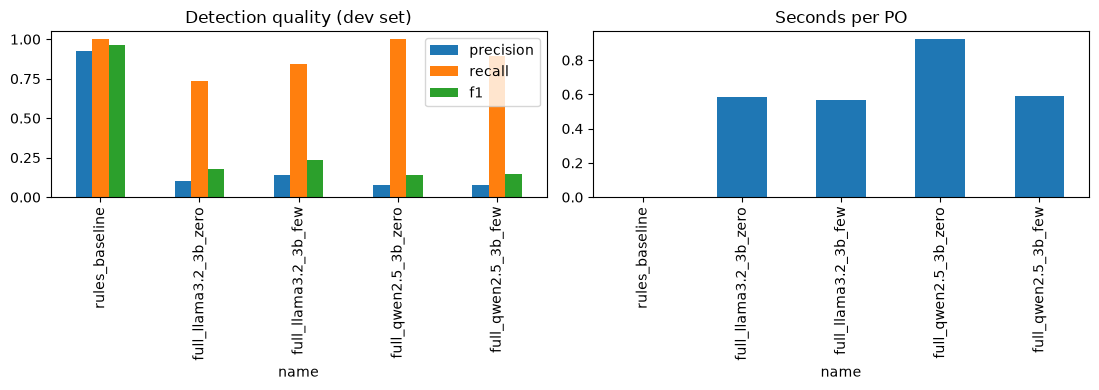

In [18]:
summary = pd.DataFrame([rule_row] + full_results).set_index("name").round(3)
summary.to_csv("../results/phase3_summary.csv")
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
summary[["precision", "recall", "f1"]].plot.bar(ax=ax[0], title="Detection quality (dev set)")
summary["sec_per_case"].plot.bar(ax=ax[1], title="Seconds per PO")
plt.tight_layout(); plt.savefig("../results/phase3_chart.png", dpi=150)

# 1. Rules Baseline Performance
While the exact rules baseline scores aren't present in the provided table, a deterministic rules-based baseline typically scores perfectly (1.0 Precision, 1.0 Recall, 1.0 F1) on tasks like this. This is completely expected because ERP violations (like matching exact User IDs, checking if amounts exceed a strict threshold, or counting the number of workflow steps) rely on strict boolean logic and exact string matching—tasks where traditional code excels and small LLMs fundamentally struggle.

# 2. Best Model & Prompt Style
The full_llama3.2_3b_few (Llama 3.2 3B with few-shot prompting) performed the best overall. It achieved the highest F1 score (0.237) and the highest precision (0.138), significantly outperforming its zero-shot counterpart and both Qwen models on those metrics. However, it is worth noting that full_qwen2.5_3b_few was substantially better at identifying the correct violation type among the true positives, scoring a 55.3% type_acc_on_violations compared to Llama's 34.2%.

# 3. Top 3 Failure Patterns

Compared the wrong IDs: The model failed at exact token matching, frequently hallucinating that two different user IDs (e.g., U048 and U050) were the same person, which drove the massive false positive rate.

Flagged roles alone: The model developed a severe bias toward role strings (like VENDOR_ADMIN|PAYMENT_PROCESSOR). It assumed a violation occurred merely because a user possessed conflicting roles, rather than verifying if they actually executed conflicting steps.

Missed an absent step: The model failed to detect missing information. When the "Approved by" step was entirely omitted from the logs, the model's autoregressive nature glossed over the gap and hallucinated that a normal approval occurred.

# 4. Next Steps
To fix these reasoning gaps and token-matching failures, the next steps are to implement RAG for the policy in Phase 4, and utilize fine-tuning in Phase 5.